<a href="https://colab.research.google.com/github/martalombardi/rhetorical_signatures/blob/main/explore_raid.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [59]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path('/content/rhetorical_signatures')
RESULTS = ROOT / 'results'
OUT = RESULTS / 'cross_genre_comparison' / 'paper'
OUT.mkdir(parents=True, exist_ok=True)
GENRES = ('abstracts', 'news', 'reddit')
HUMAN = 'Human'
LABELS = {'abstracts':'Abstracts · all · 6–10 sentences',
          'news':'News · first 200 · 10 sentences',
          'reddit':'Reddit · first 200 · 10 sentences'}
plt.rcParams.update({'font.size':12, 'axes.titlesize':13, 'axes.labelsize':11,
                     'figure.dpi':135, 'savefig.dpi':300, 'pdf.fonttype':42,
                     'axes.spines.top':False, 'axes.spines.right':False})

# Optional explicit paths, if several runs share the same genre:
OVERRIDE = {g:{} for g in GENRES}  # e.g. OVERRIDE['abstracts']['structural'] = '/.../structural_analysis/...'
def genre_of(p):
    s = str(p).lower()
    m = re.search(r'(?:domain|genre)[-_](abstracts?|news|reddit)(?=[_./-]|$)', s)
    if m: return 'abstracts' if m.group(1).startswith('abstract') else m.group(1)
    m = re.search(r'(?<![a-z])(abstracts?|news|reddit)(?![a-z])', s)
    return ('abstracts' if m.group(1).startswith('abstract') else m.group(1)) if m else None

def score(p,g):
    s = str(p).lower()
    if g == 'abstracts':
        return 30*('6-10' in s or 'n_sentences-6' in s) - 40*('first200' in s or 'first_200' in s)
    return 30*any(x in s for x in ('first200','first_200','first-200')) + 15*('10-10' in s or 'n_sentences-10' in s)

FAMILIES = {
    'structural':'tree_metrics.csv',
    'bootstrap':'bootstrap_means.csv',
    'divergence':'js_human_vs_llm.csv',
    'diversity':'motif_document_diversity.csv'
}
PATHS = {}
for g in GENRES:
    PATHS[g] = {}
    for fam, fname in FAMILIES.items():
        if fam in OVERRIDE[g]:
            folder = Path(OVERRIDE[g][fam])
        else:
            candidates = [p.parent for p in RESULTS.rglob(fname)
                          if genre_of(p) == g and 'cross_genre_comparison' not in str(p)]
            if not candidates:
                raise FileNotFoundError(f'{g}: missing {fname}; set OVERRIDE[{g!r}][{fam!r}]')
            folder = sorted(candidates, key=lambda p:(score(p,g),str(p)))[-1]
        PATHS[g][fam] = folder
    PATHS[g]['diversity'] = PATHS[g]['divergence'] if (PATHS[g]['divergence']/'motif_document_diversity.csv').exists() else PATHS[g]['diversity']

def read(g,fam,name):
    return pd.read_csv(PATHS[g][fam] / (name + '.csv'))

def ordered_sources(values):
    a = sorted(set(values))
    return ([HUMAN] if HUMAN in a else []) + [x for x in a if x != HUMAN]

SOURCES = ordered_sources(set().union(*(set(read(g,'structural','tree_metrics').source) for g in GENRES)))
LLMS = [s for s in SOURCES if s != HUMAN]
COLORS = dict(zip(SOURCES,plt.get_cmap('tab20').colors[:len(SOURCES)]))

def finish(fig,stem):
    fig.savefig(OUT/(stem+'.pdf'),bbox_inches='tight')
    fig.savefig(OUT/(stem+'.png'),dpi=300,bbox_inches='tight')
    plt.show()
    plt.close(fig)

def matrix_axes(nrows,ncols,cell_w=4.4,cell_h=3.5):
    fig,axs=plt.subplots(nrows,ncols,figsize=(max(10,ncols*cell_w),nrows*cell_h),
                         squeeze=False,layout='constrained')
    return fig,axs

def missing(ax):
    ax.text(.5,.5,'No data',ha='center',va='center',transform=ax.transAxes,color='.5')
    ax.set_axis_off()


# Layout comune: una metrica per riga, un genere per colonna.
def genre_grid(metrics, draw, stem, title, row_h=5.2):
    fig, axes = plt.subplots(len(metrics), 3, figsize=(25, row_h*len(metrics)),
                             squeeze=False, layout='constrained')
    for i, (metric, ylabel) in enumerate(metrics):
        for j, genre in enumerate(GENRES):
            ax = axes[i, j]
            draw(ax, genre, metric)
            if i == 0:
                ax.set_title(genre.title(), fontsize=17, fontweight='bold', pad=14)
            if j == 0:
                ax.set_ylabel(ylabel, fontsize=14)
            ax.grid(axis='y', alpha=.17)
    fig.suptitle(title, fontsize=19, fontweight='bold')
    finish(fig, stem)

def source_boxplot(ax, df, metric):
    data = [df.loc[df.source.eq(s), metric].dropna().to_numpy(float)
            for s in SOURCES]
    bp = ax.boxplot(data, patch_artist=True, showfliers=True,
                    medianprops={'color':'black','linewidth':1.6},
                    flierprops={'markersize':2.5,'alpha':.4})
    for box, s in zip(bp['boxes'], SOURCES):
        box.set_facecolor(COLORS[s])
        box.set_alpha(.72)
    ax.set_xticks(range(1, len(SOURCES)+1), SOURCES, rotation=45, ha='right')
    ax.tick_params(axis='x', labelsize=10)

def source_intervals(ax, df, metric, mode):
    col = 'mean' if mode == 'means' else 'delta'
    models = SOURCES if mode == 'means' else LLMS
    sub = df.loc[df.metric.eq(metric)].set_index('source')
    for j,s in enumerate(models):
        if s not in sub.index:
            continue
        r = sub.loc[s]
        center,lo,hi = float(r[col]),float(r.ci_low),float(r.ci_high)
        ax.errorbar(j,center,yerr=[[max(0,center-lo)],[max(0,hi-center)]],
                    fmt='o',capsize=4,markersize=6,color=COLORS[s],elinewidth=1.6)
    if mode == 'deltas':
        ax.axhline(0,color='.4',ls='--',lw=1)
    ax.set_xticks(range(len(models)),models,rotation=45,ha='right')
    ax.tick_params(axis='x',labelsize=10)


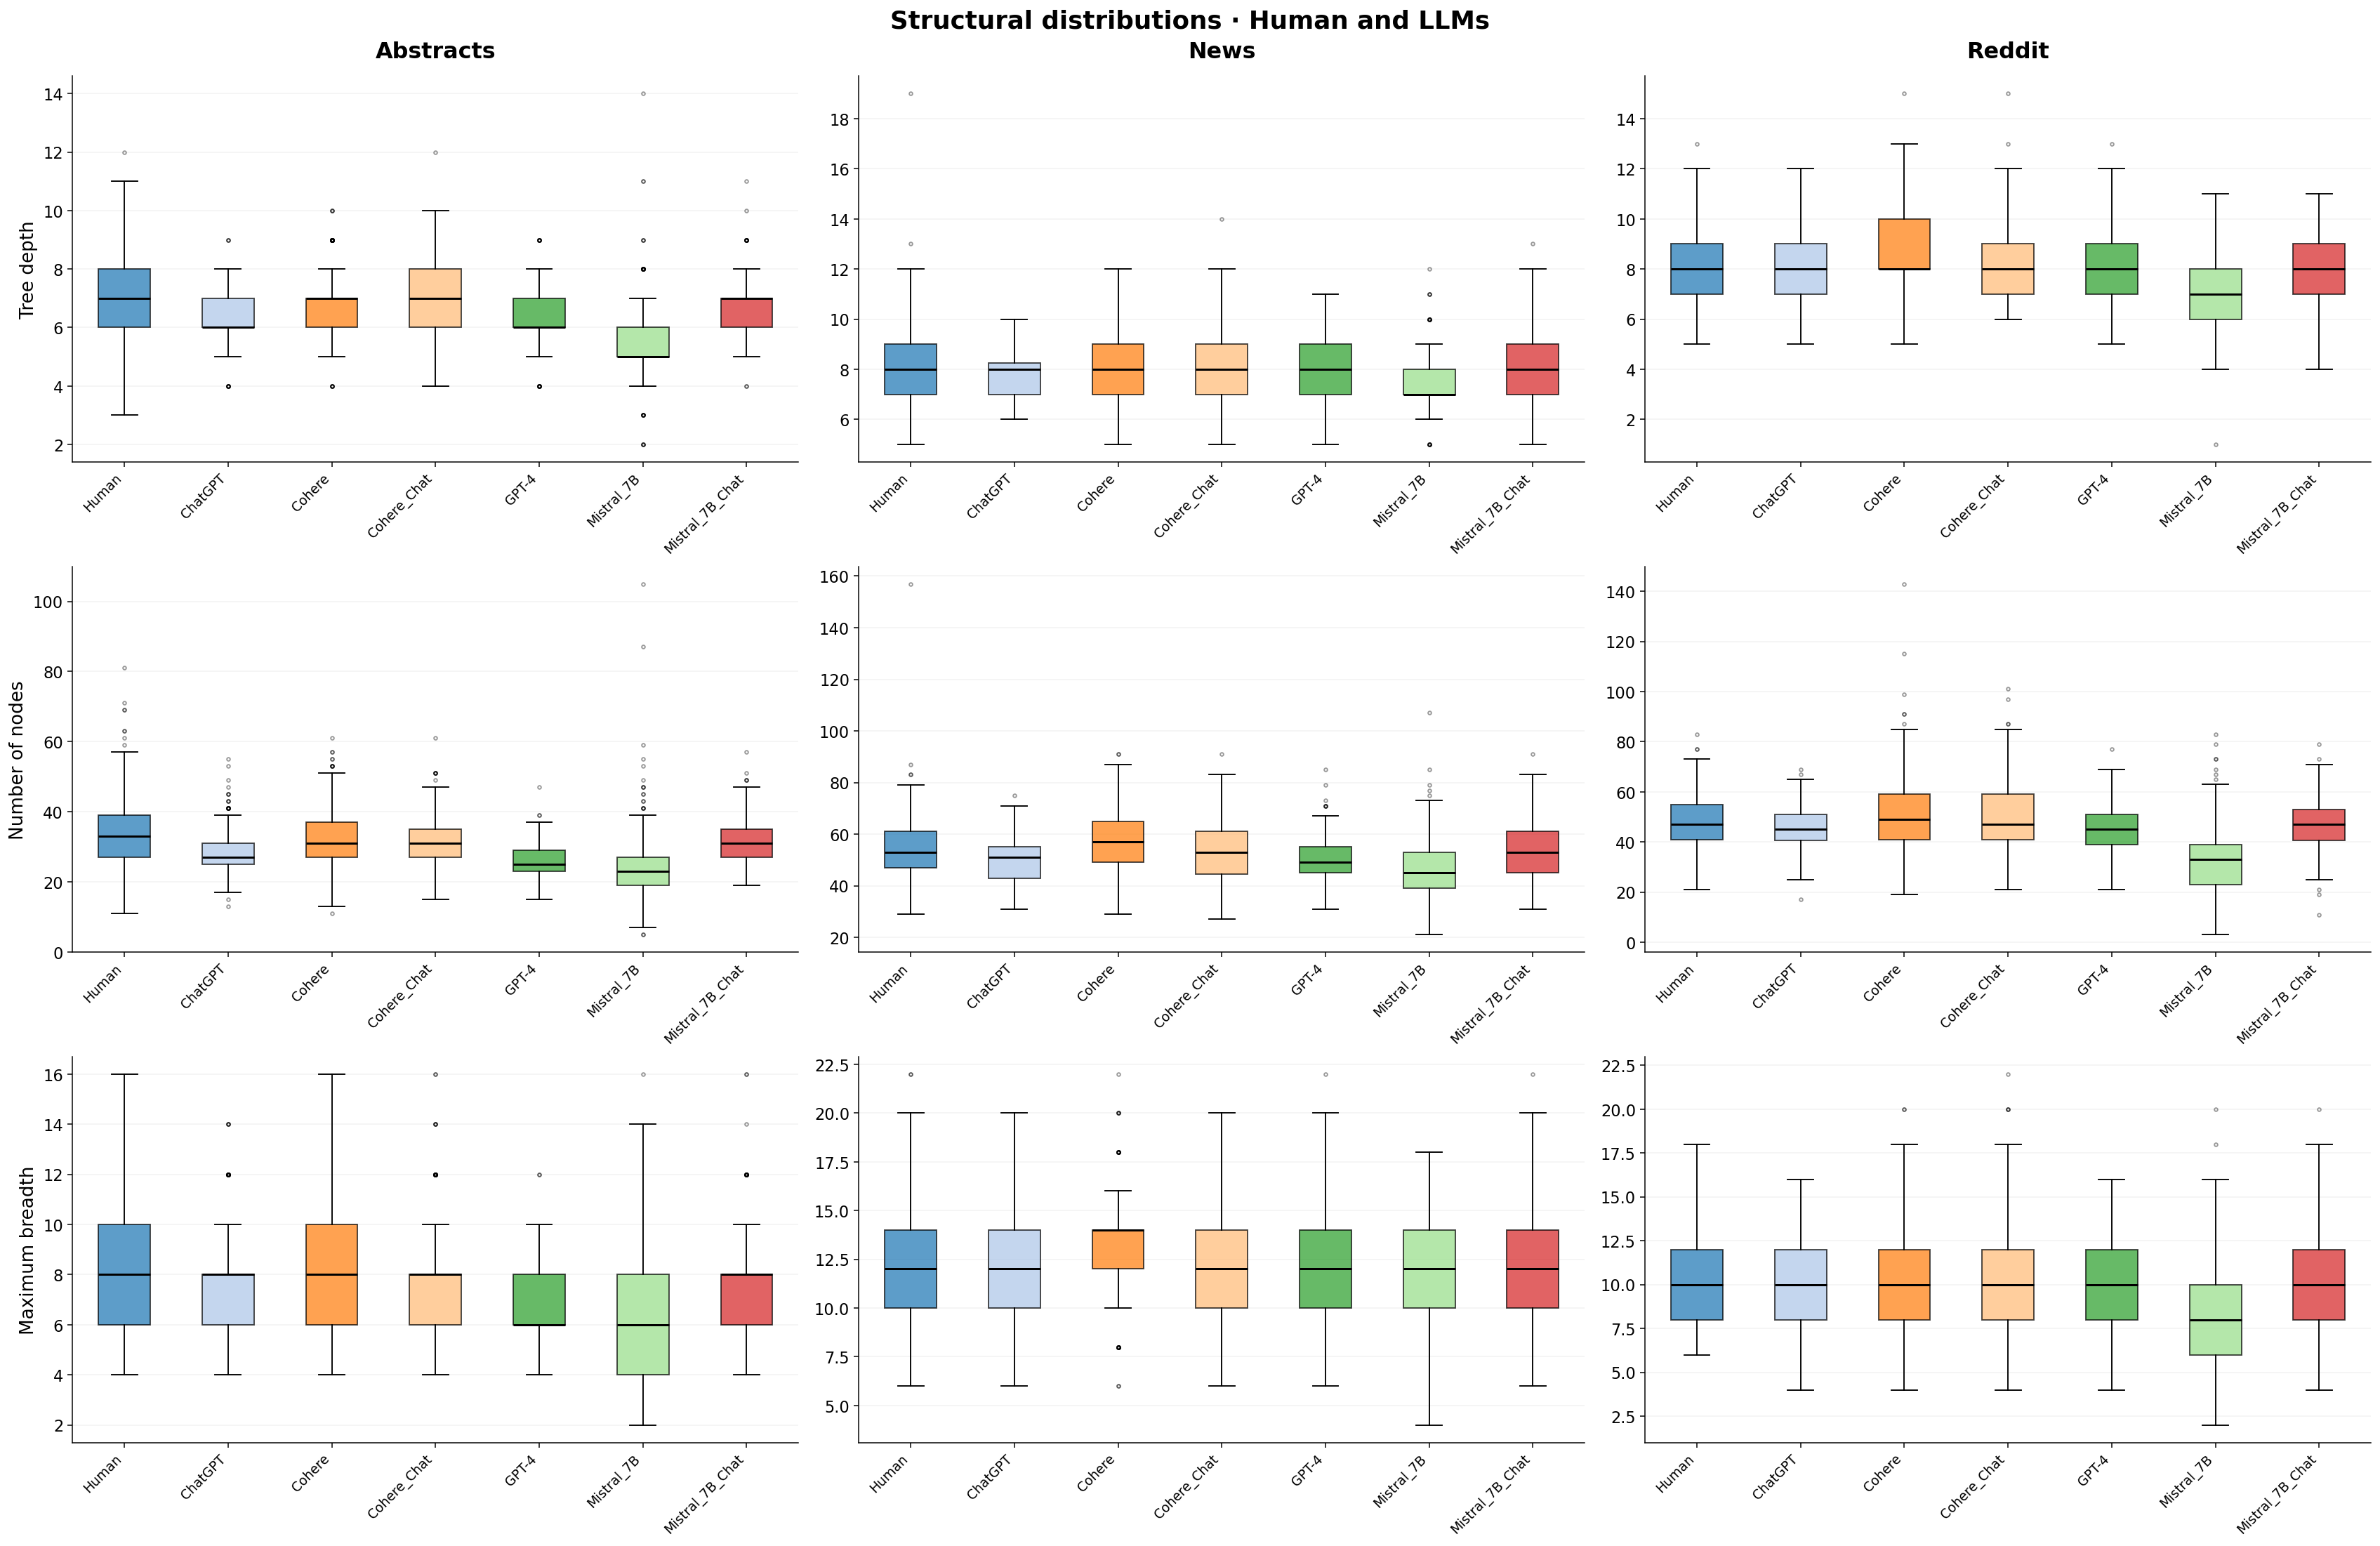

In [60]:
STRUCT = [('depth','Tree depth'),('number_of_nodes','Number of nodes'),
          ('max_breadth','Maximum breadth')]
structural = {g:read(g,'structural','tree_metrics') for g in GENRES}
genre_grid(STRUCT,
           lambda ax,g,m:source_boxplot(ax,structural[g],m),
           'structural_boxplots_comparison','Structural distributions · Human and LLMs',
           row_h=5.4)

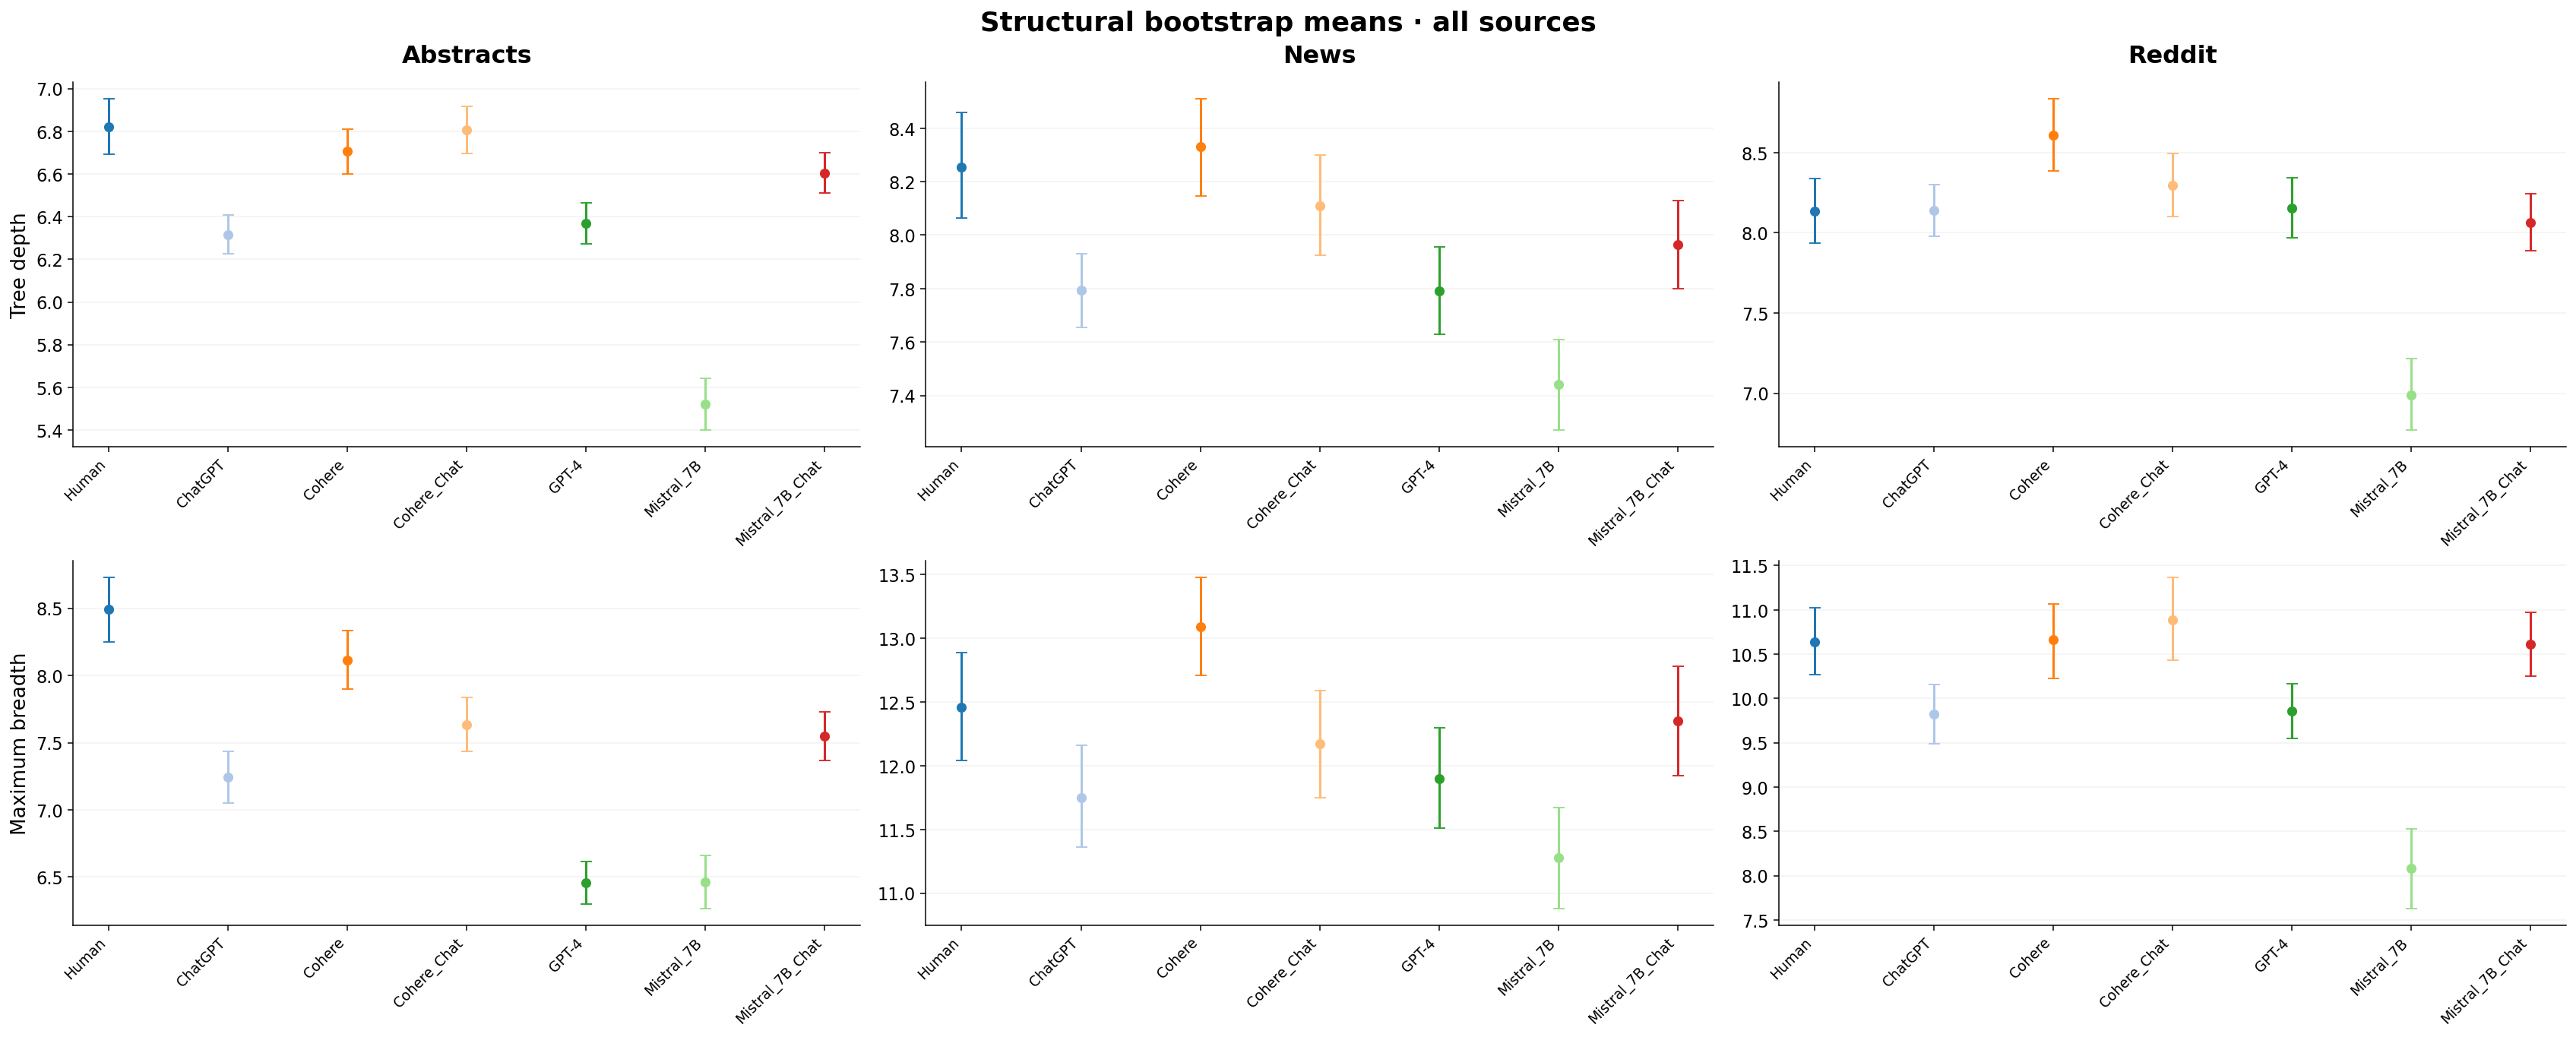

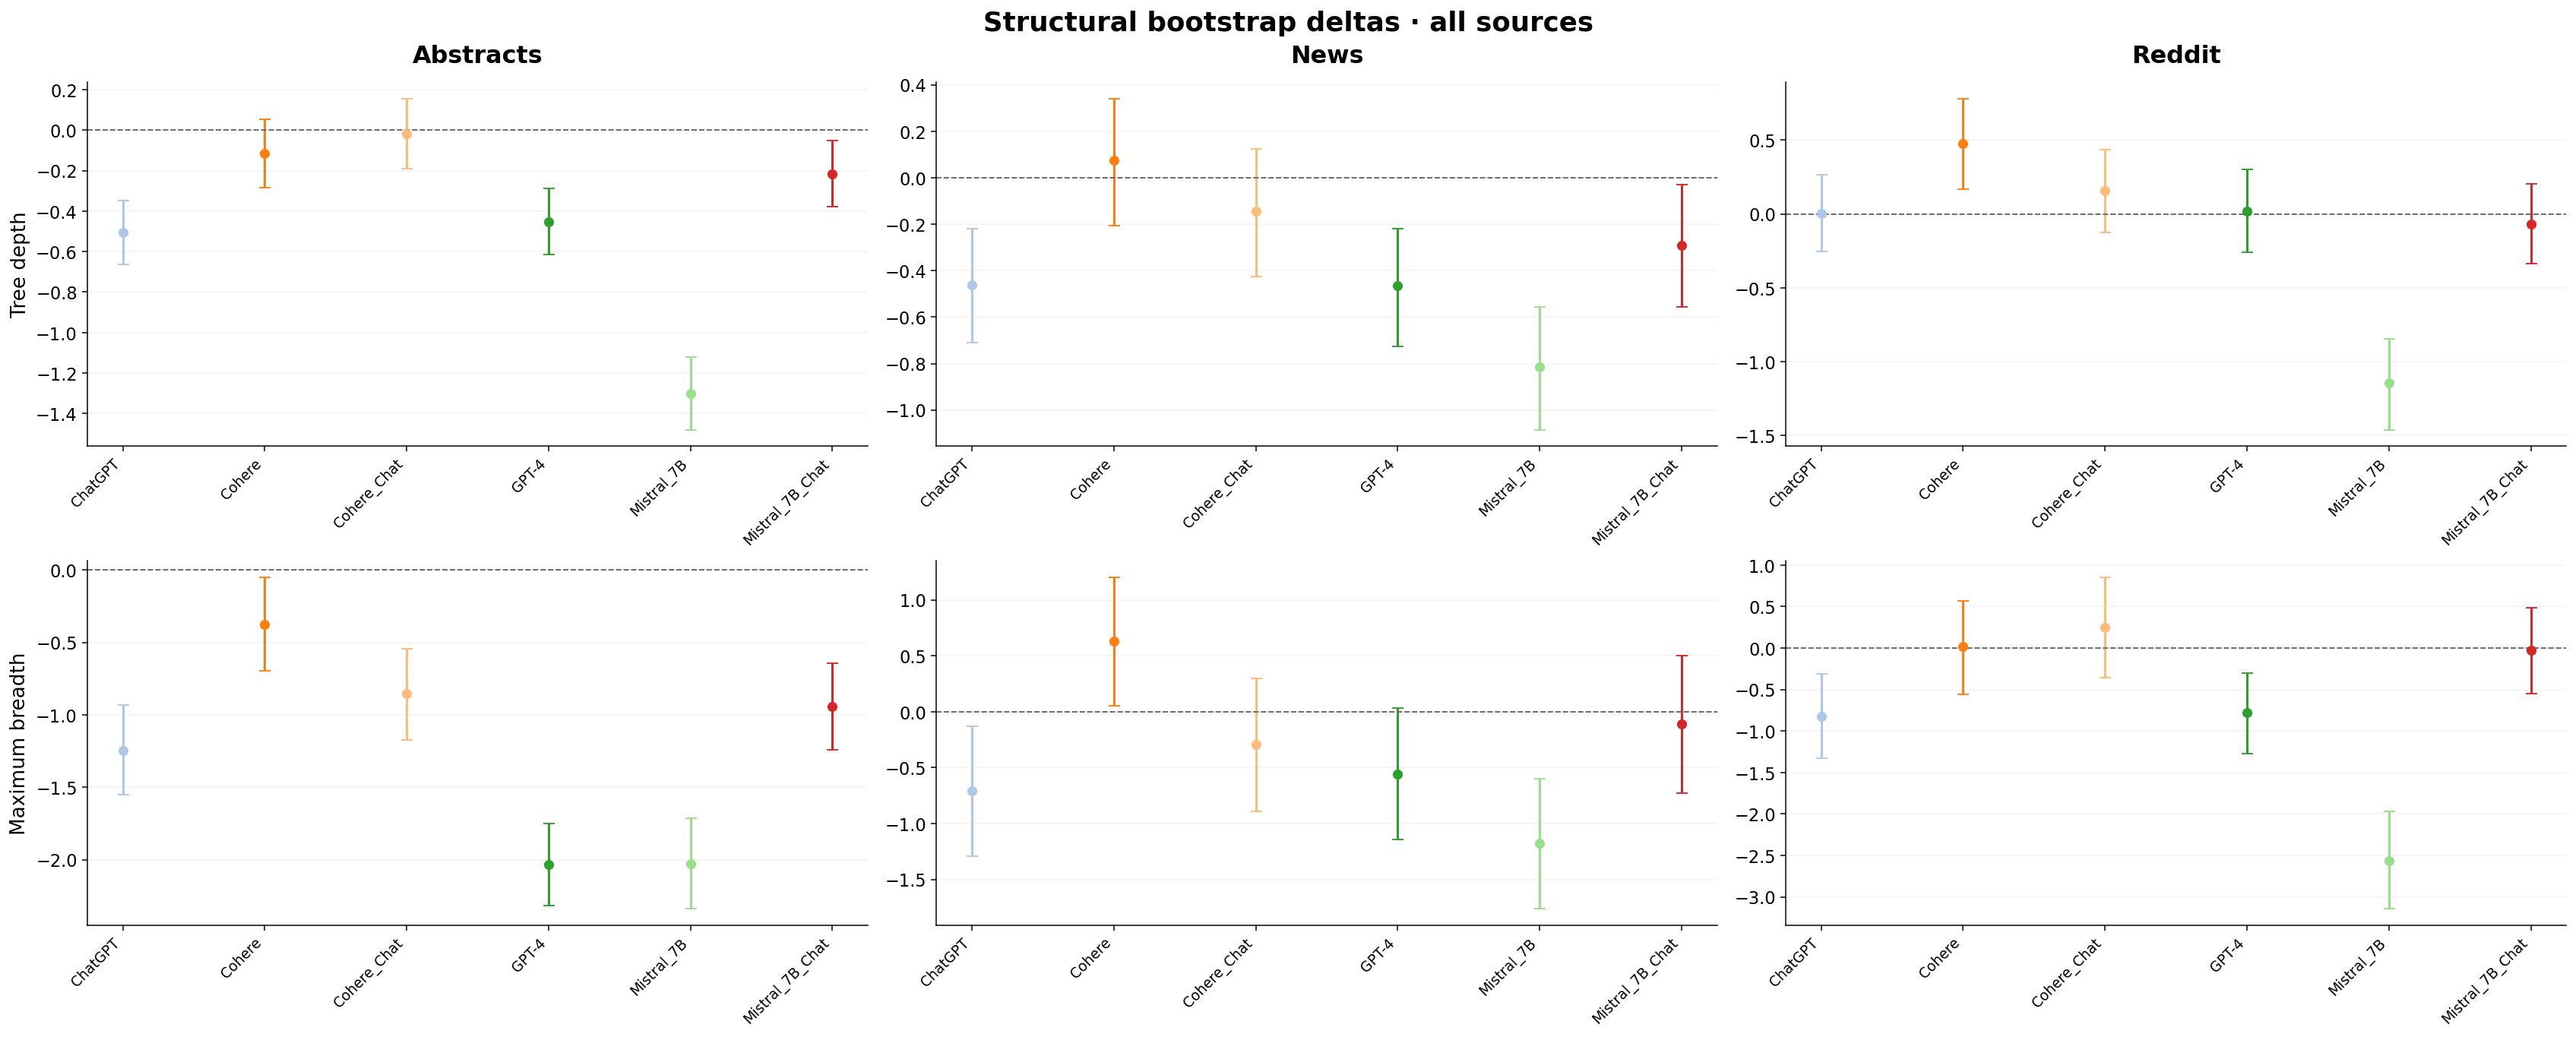

In [61]:
STRUCT_BOOT = [('depth','Tree depth'),('number_of_nodes','Number of nodes'),
               ('max_breadth','Maximum breadth')]
for mode,filename in [('means','bootstrap_means'),('deltas','bootstrap_deltas')]:
    data = {g:read(g,'bootstrap',filename) for g in GENRES}
    metrics = [(m,label) for m,label in STRUCT_BOOT
               if any(m in set(data[g].metric) for g in GENRES)]
    genre_grid(metrics,
               lambda ax,g,m:source_intervals(ax,data[g],m,mode),
               f'structural_bootstrap_{mode}_comparison',
               f'Structural bootstrap {mode} · all sources',row_h=5)

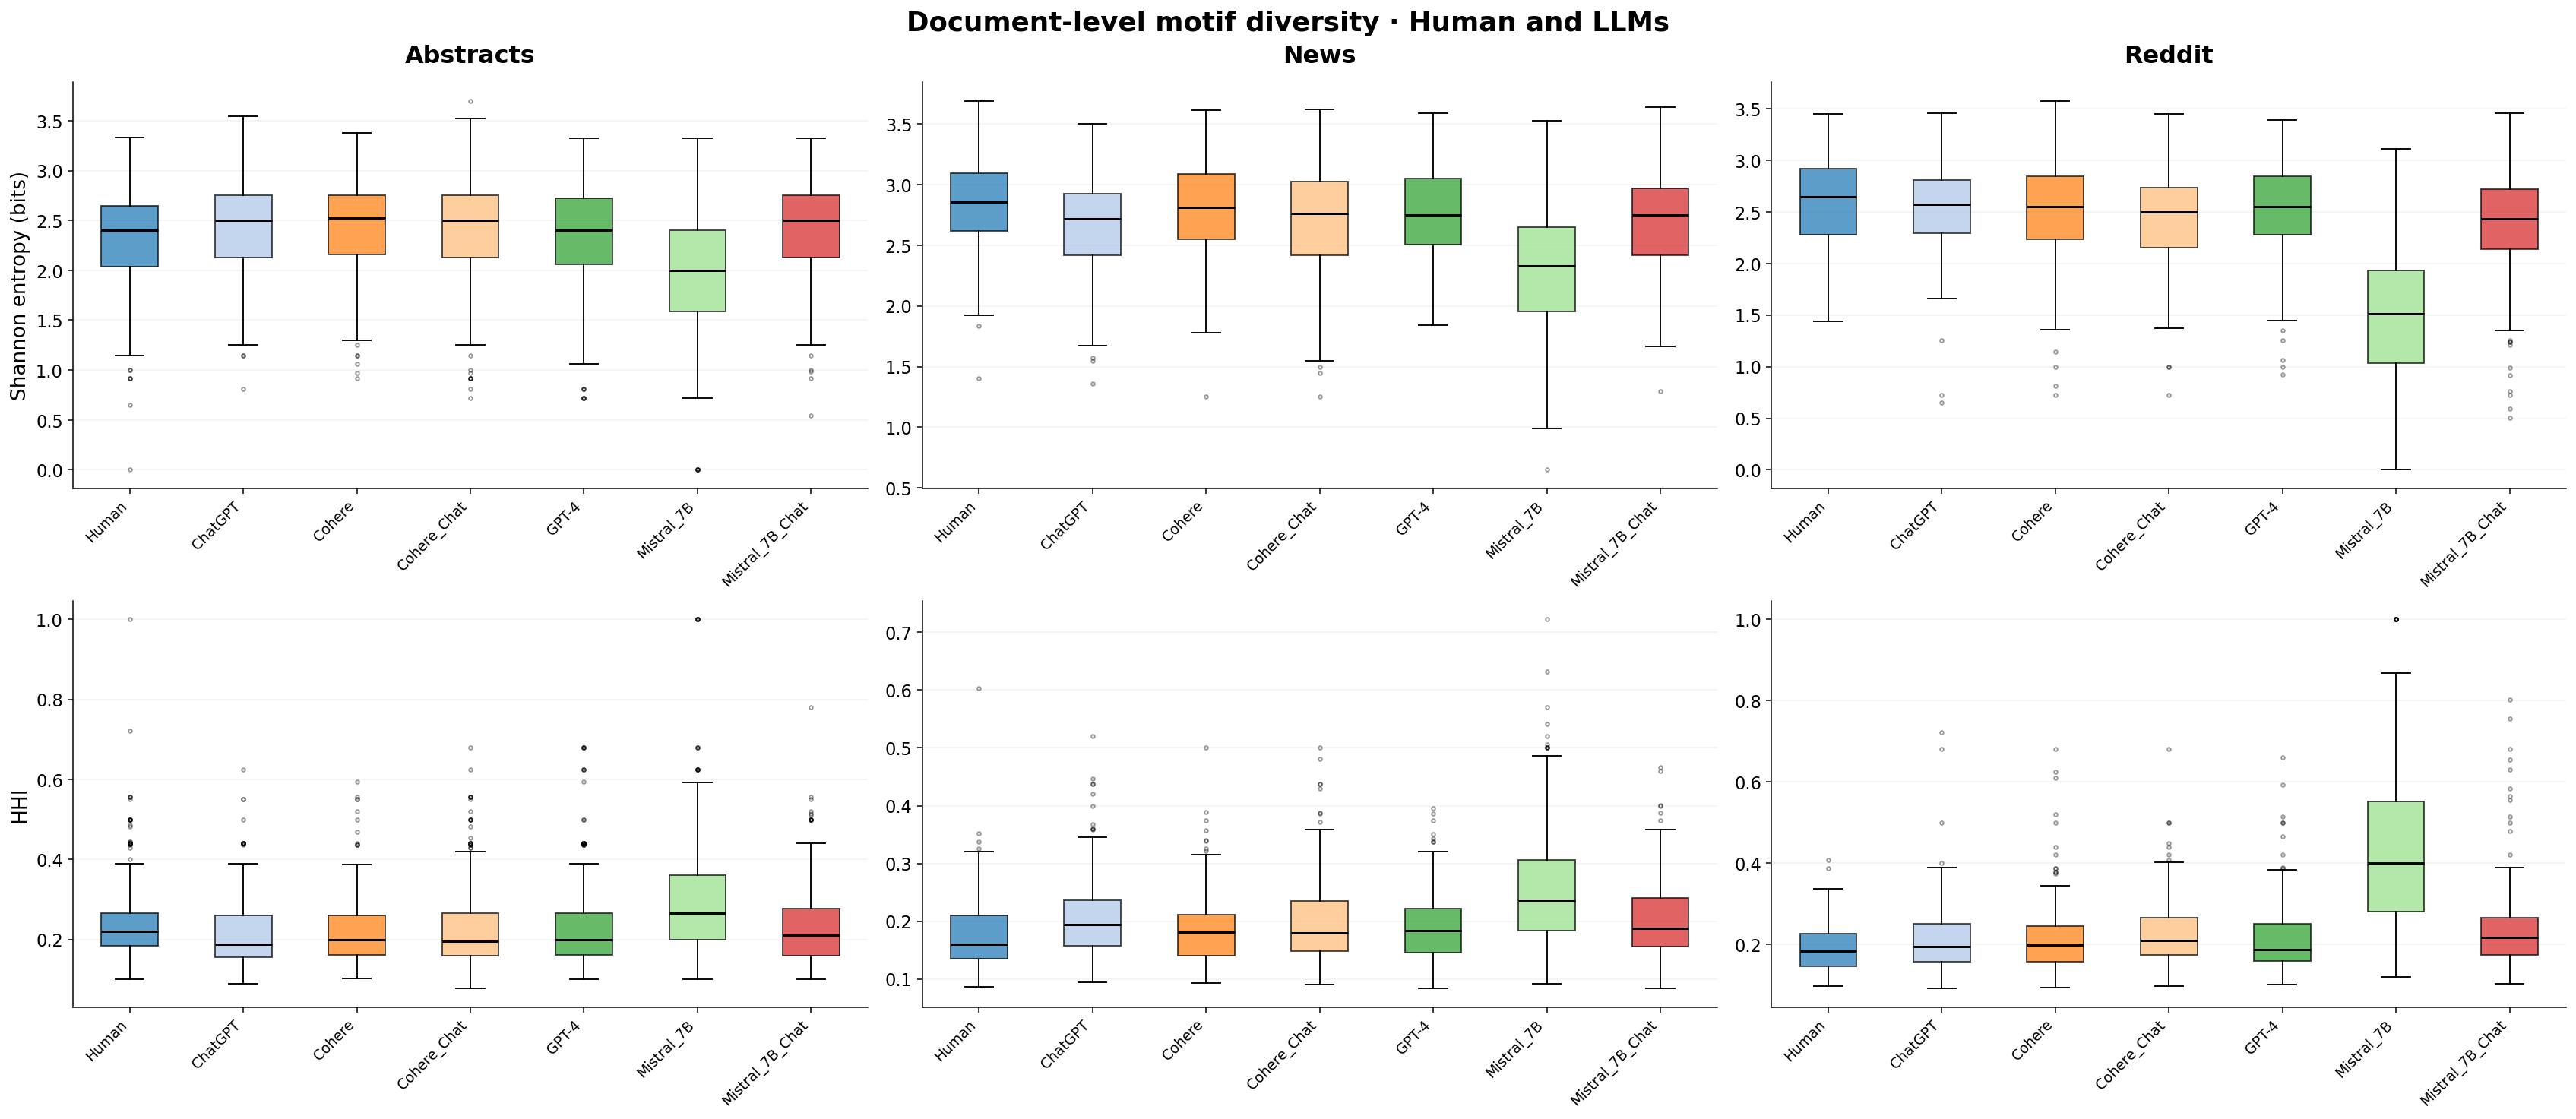

In [62]:
DIVERSITY = [('entropy_bits','Shannon entropy (bits)'),('hhi','HHI')]
diversity = {g:read(g,'diversity','motif_document_diversity') for g in GENRES}
genre_grid(DIVERSITY,
           lambda ax,g,m:source_boxplot(ax,diversity[g],m),
           'motif_diversity_boxplots_comparison',
           'Document-level motif diversity · Human and LLMs',row_h=5.4)

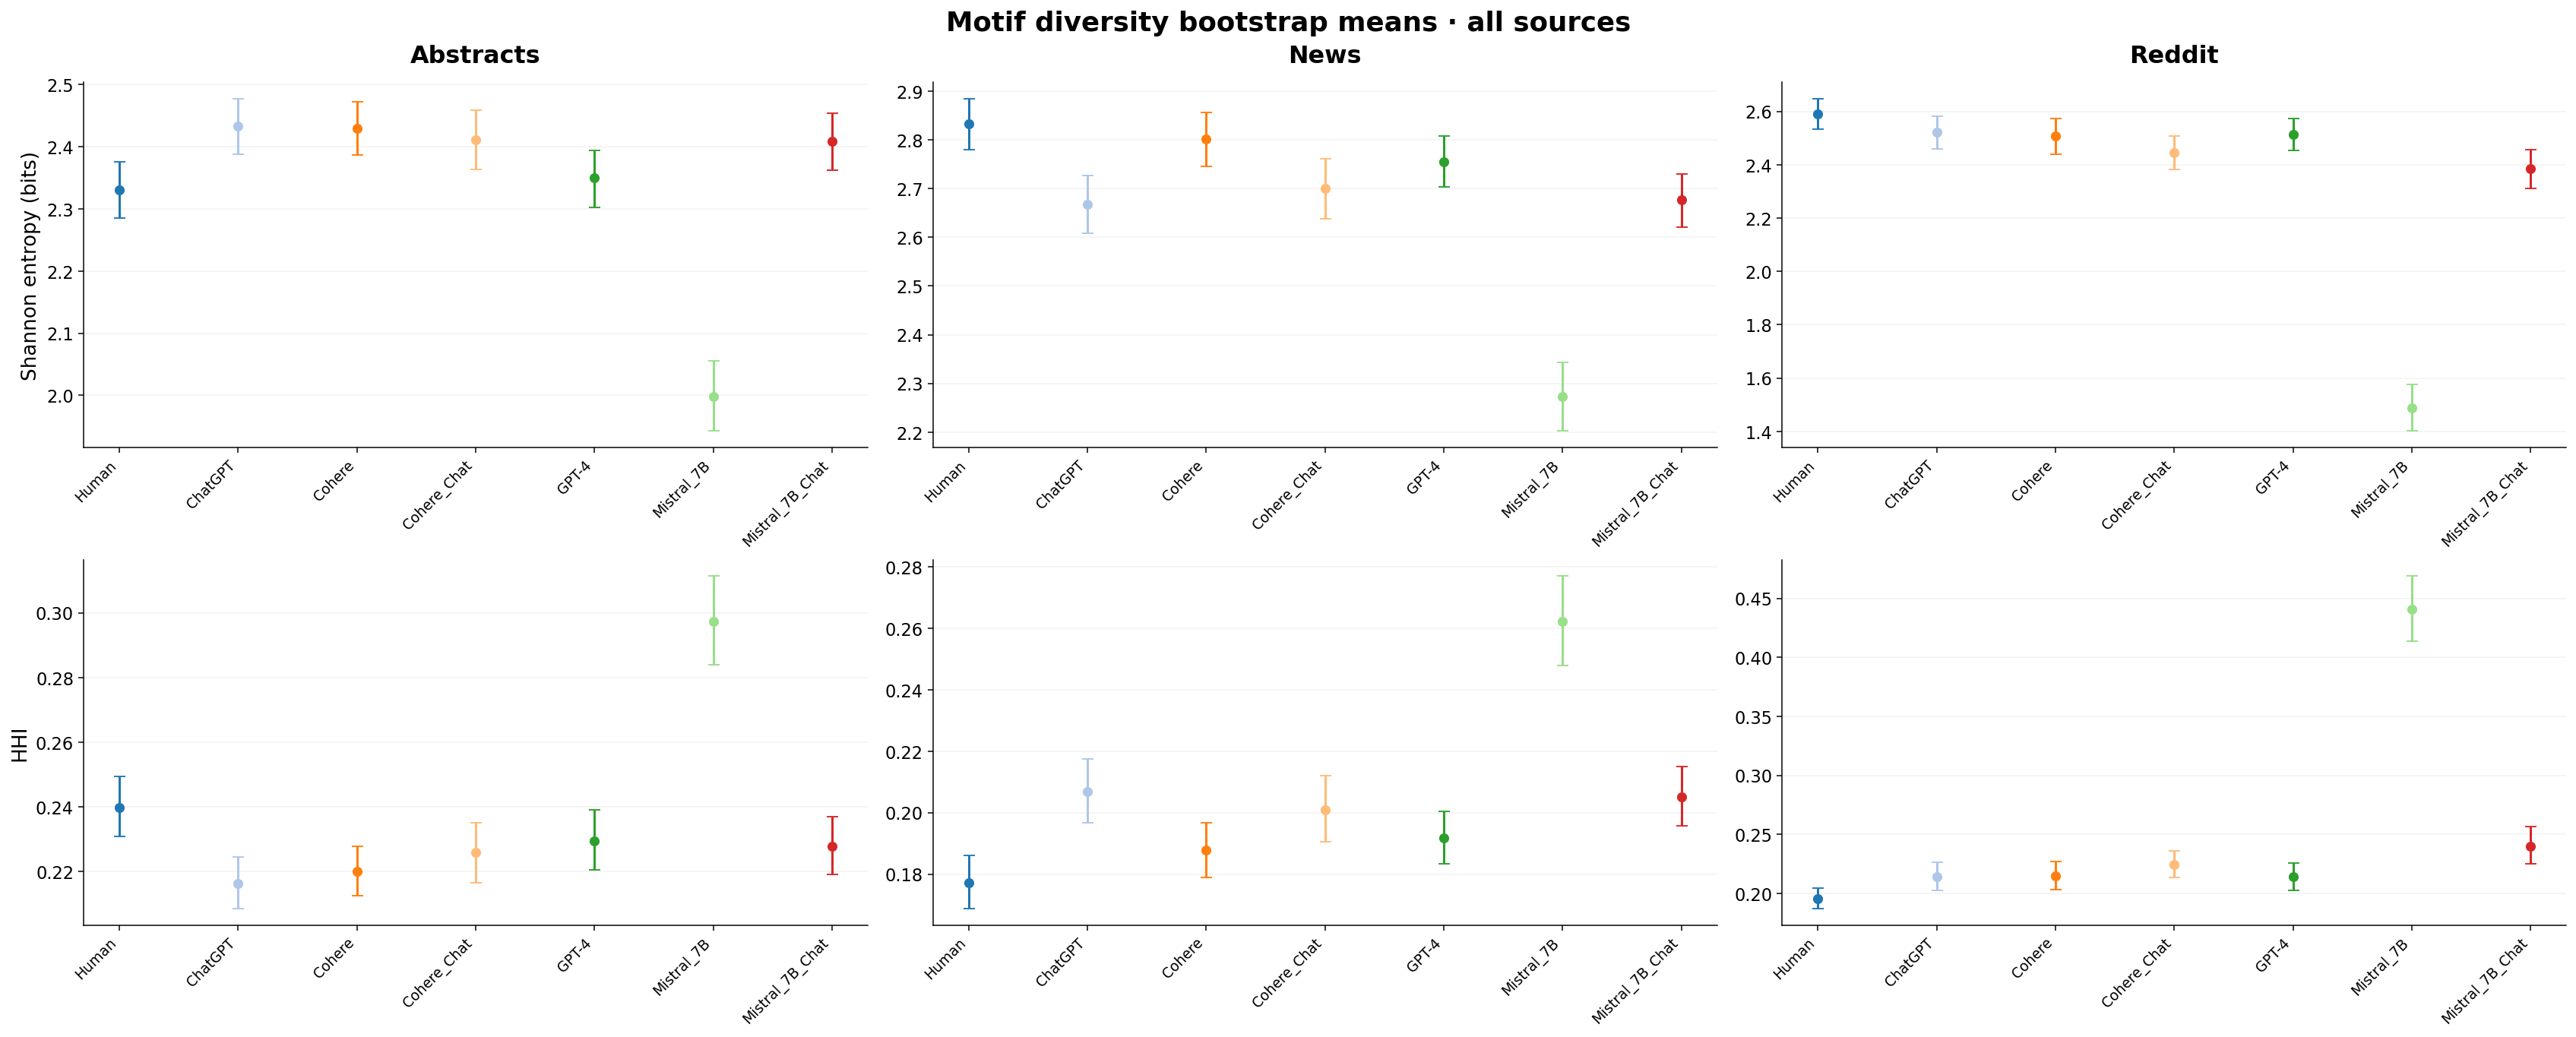

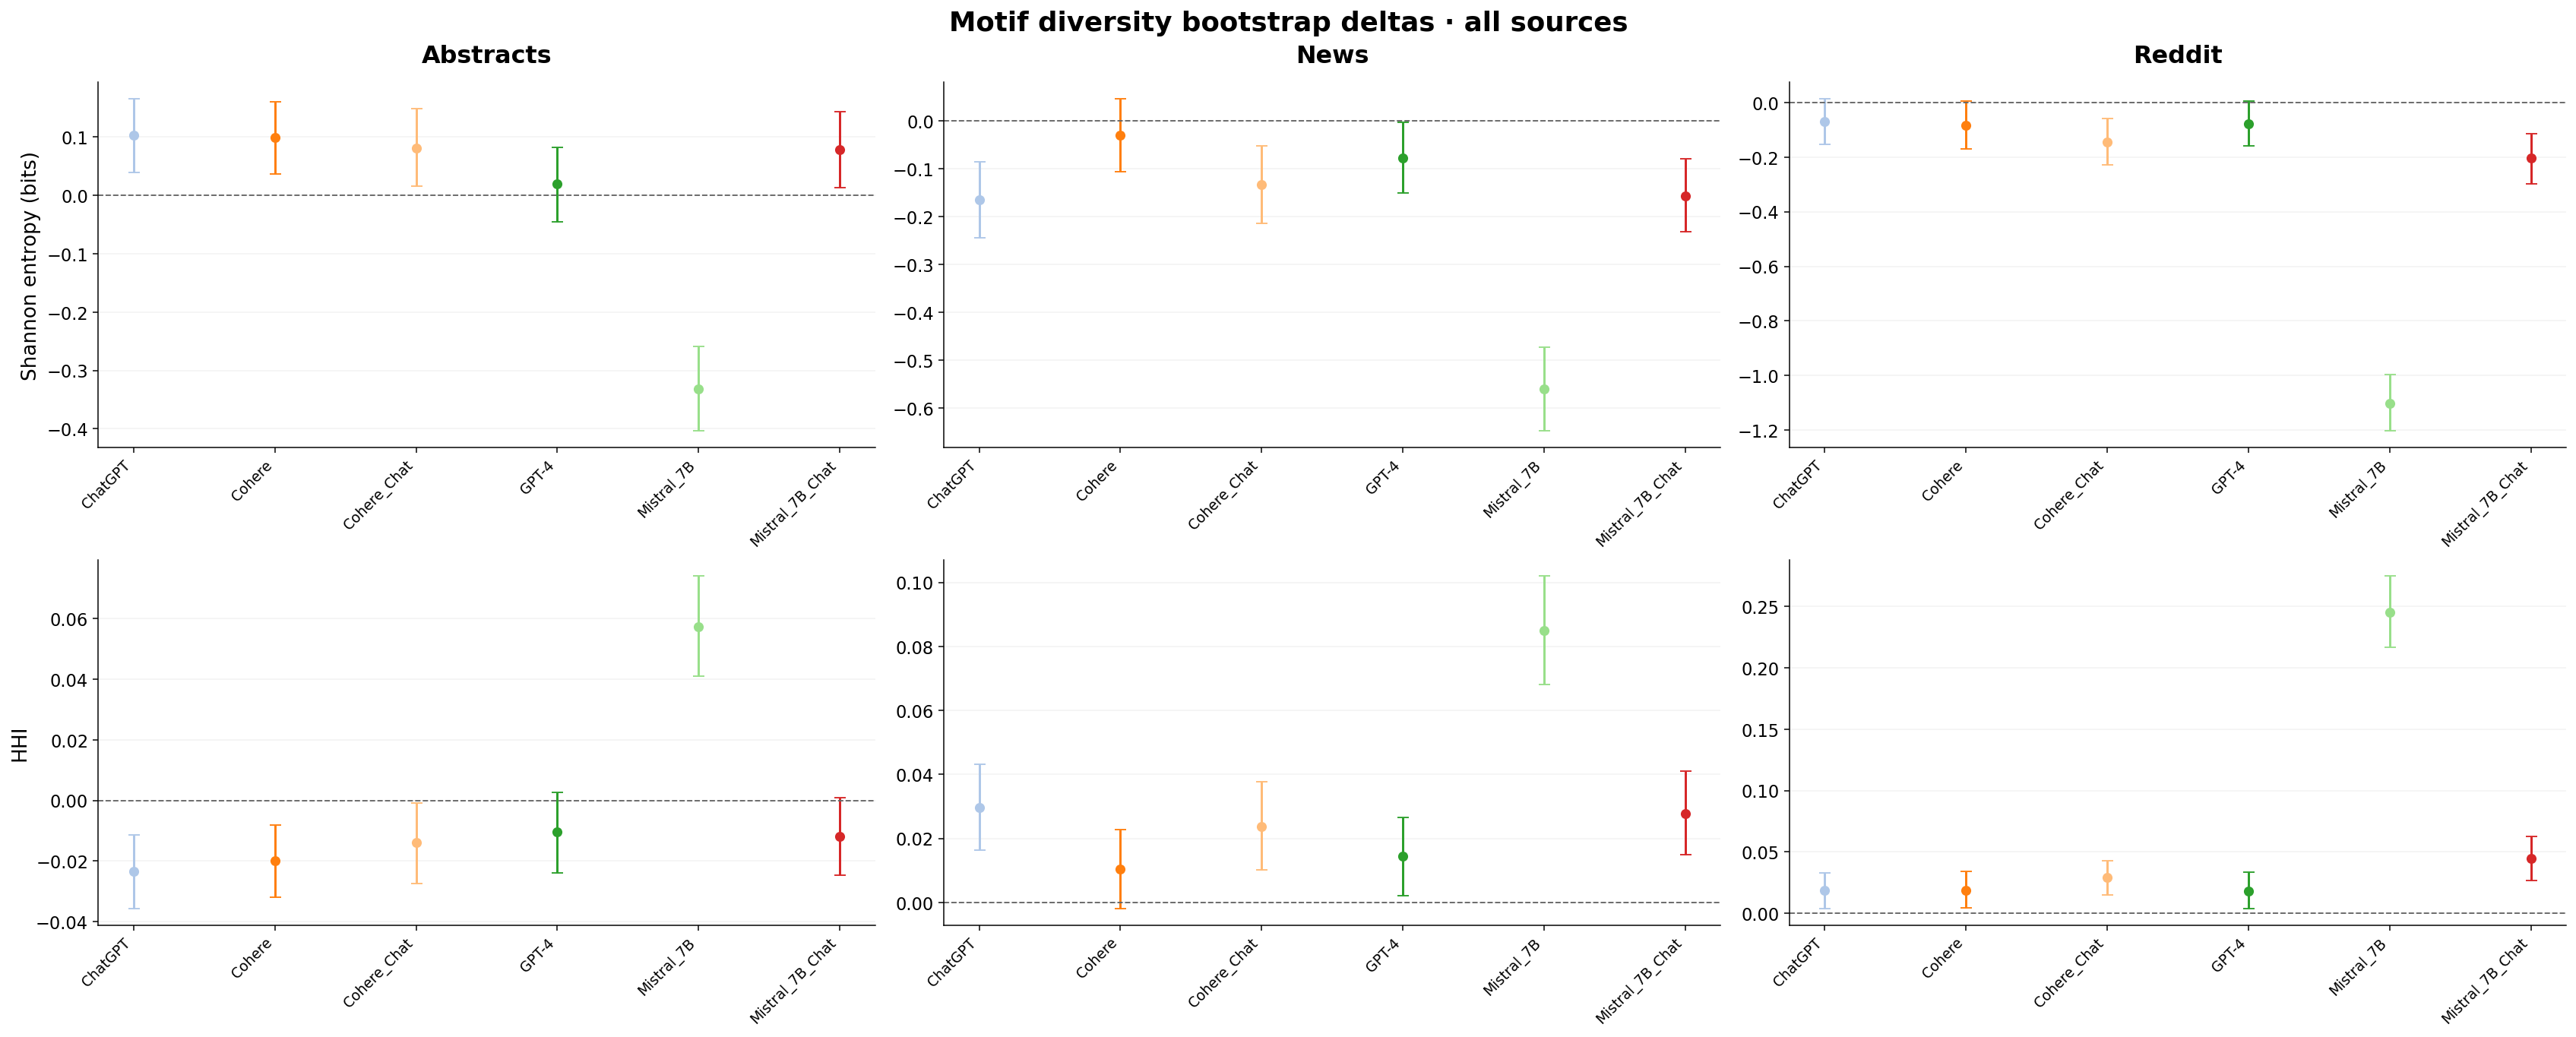

In [63]:
for mode,filename in [('means','motif_diversity_summary'),
                      ('deltas','motif_diversity_deltas')]:
    data={g:read(g,'diversity',filename) for g in GENRES}
    genre_grid(DIVERSITY,
               lambda ax,g,m:source_intervals(ax,data[g],m,mode),
               f'motif_diversity_bootstrap_{mode}_comparison',
               f'Motif diversity bootstrap {mode} · all sources',row_h=5)

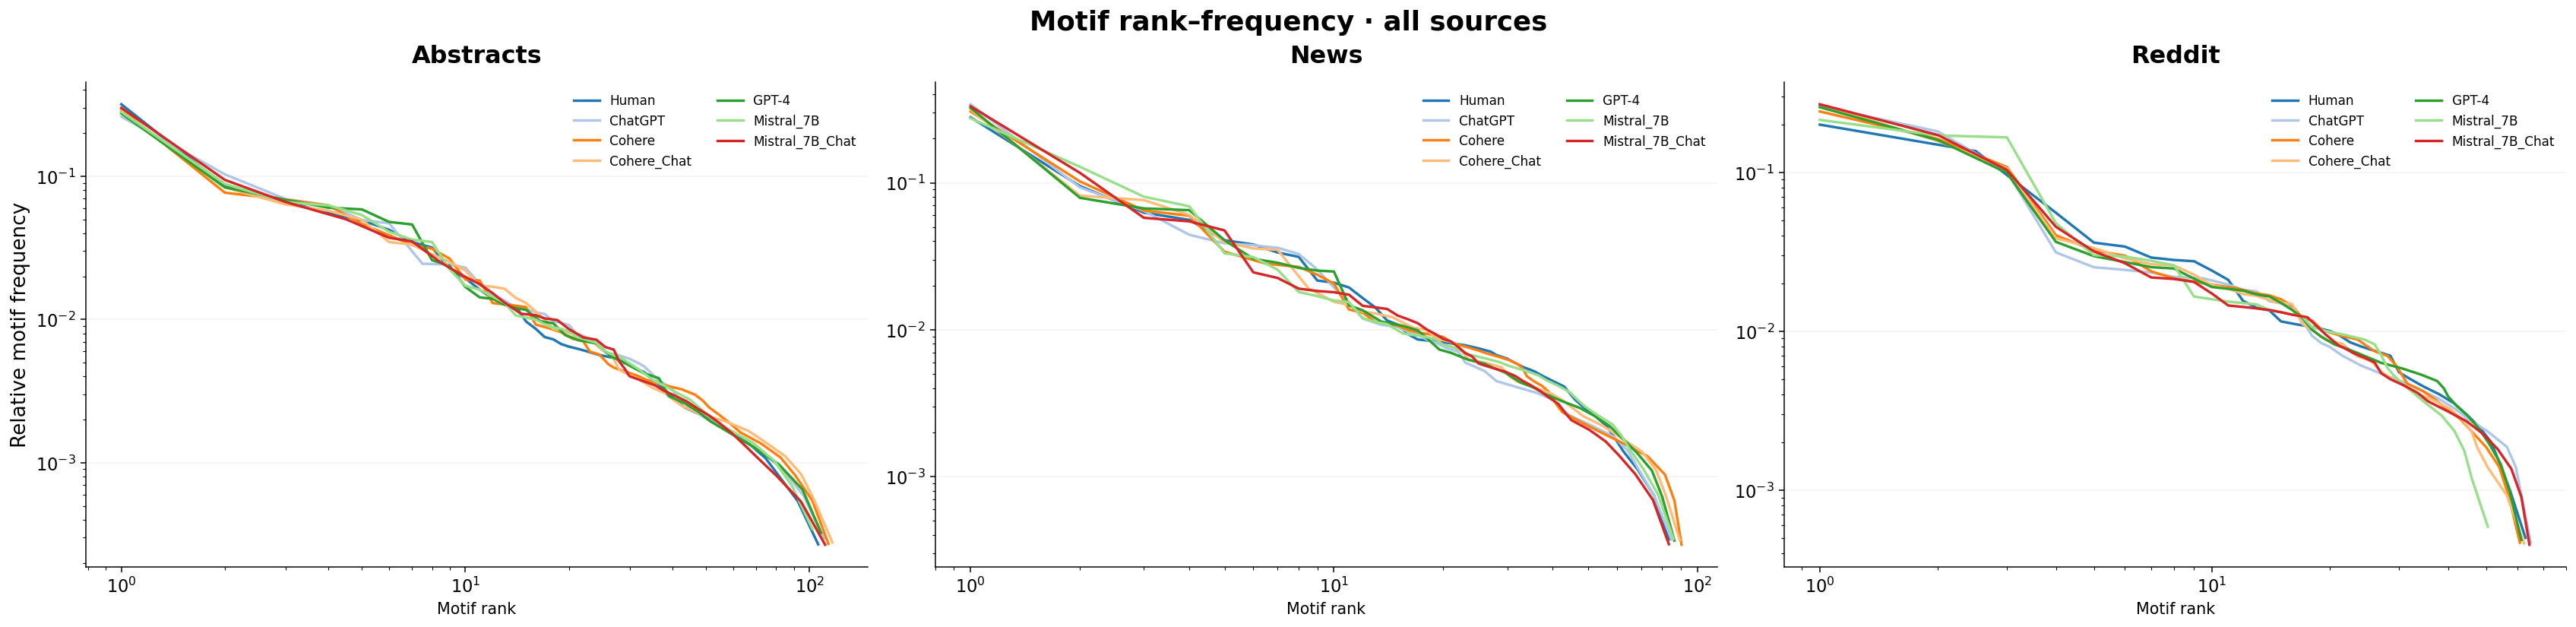

In [64]:
rank = {g:read(g,'divergence','rank_data') for g in GENRES}
def draw_rank(ax,g,metric):
    df=rank[g]
    for s in SOURCES:
        sub=df.loc[df.source.eq(s)].sort_values('rank')
        sub=sub.loc[(sub['rank']>0)&(sub['relative_frequency']>0)]
        if len(sub):
            ax.plot(sub['rank'],sub['relative_frequency'],label=s,
                    color=COLORS[s],lw=1.8)
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xlabel('Motif rank')
    ax.legend(fontsize=9,loc='best',frameon=False,ncol=2)
genre_grid([('rank','Relative motif frequency')],draw_rank,
           'rank_frequency_comparison','Motif rank–frequency · all sources',row_h=6)

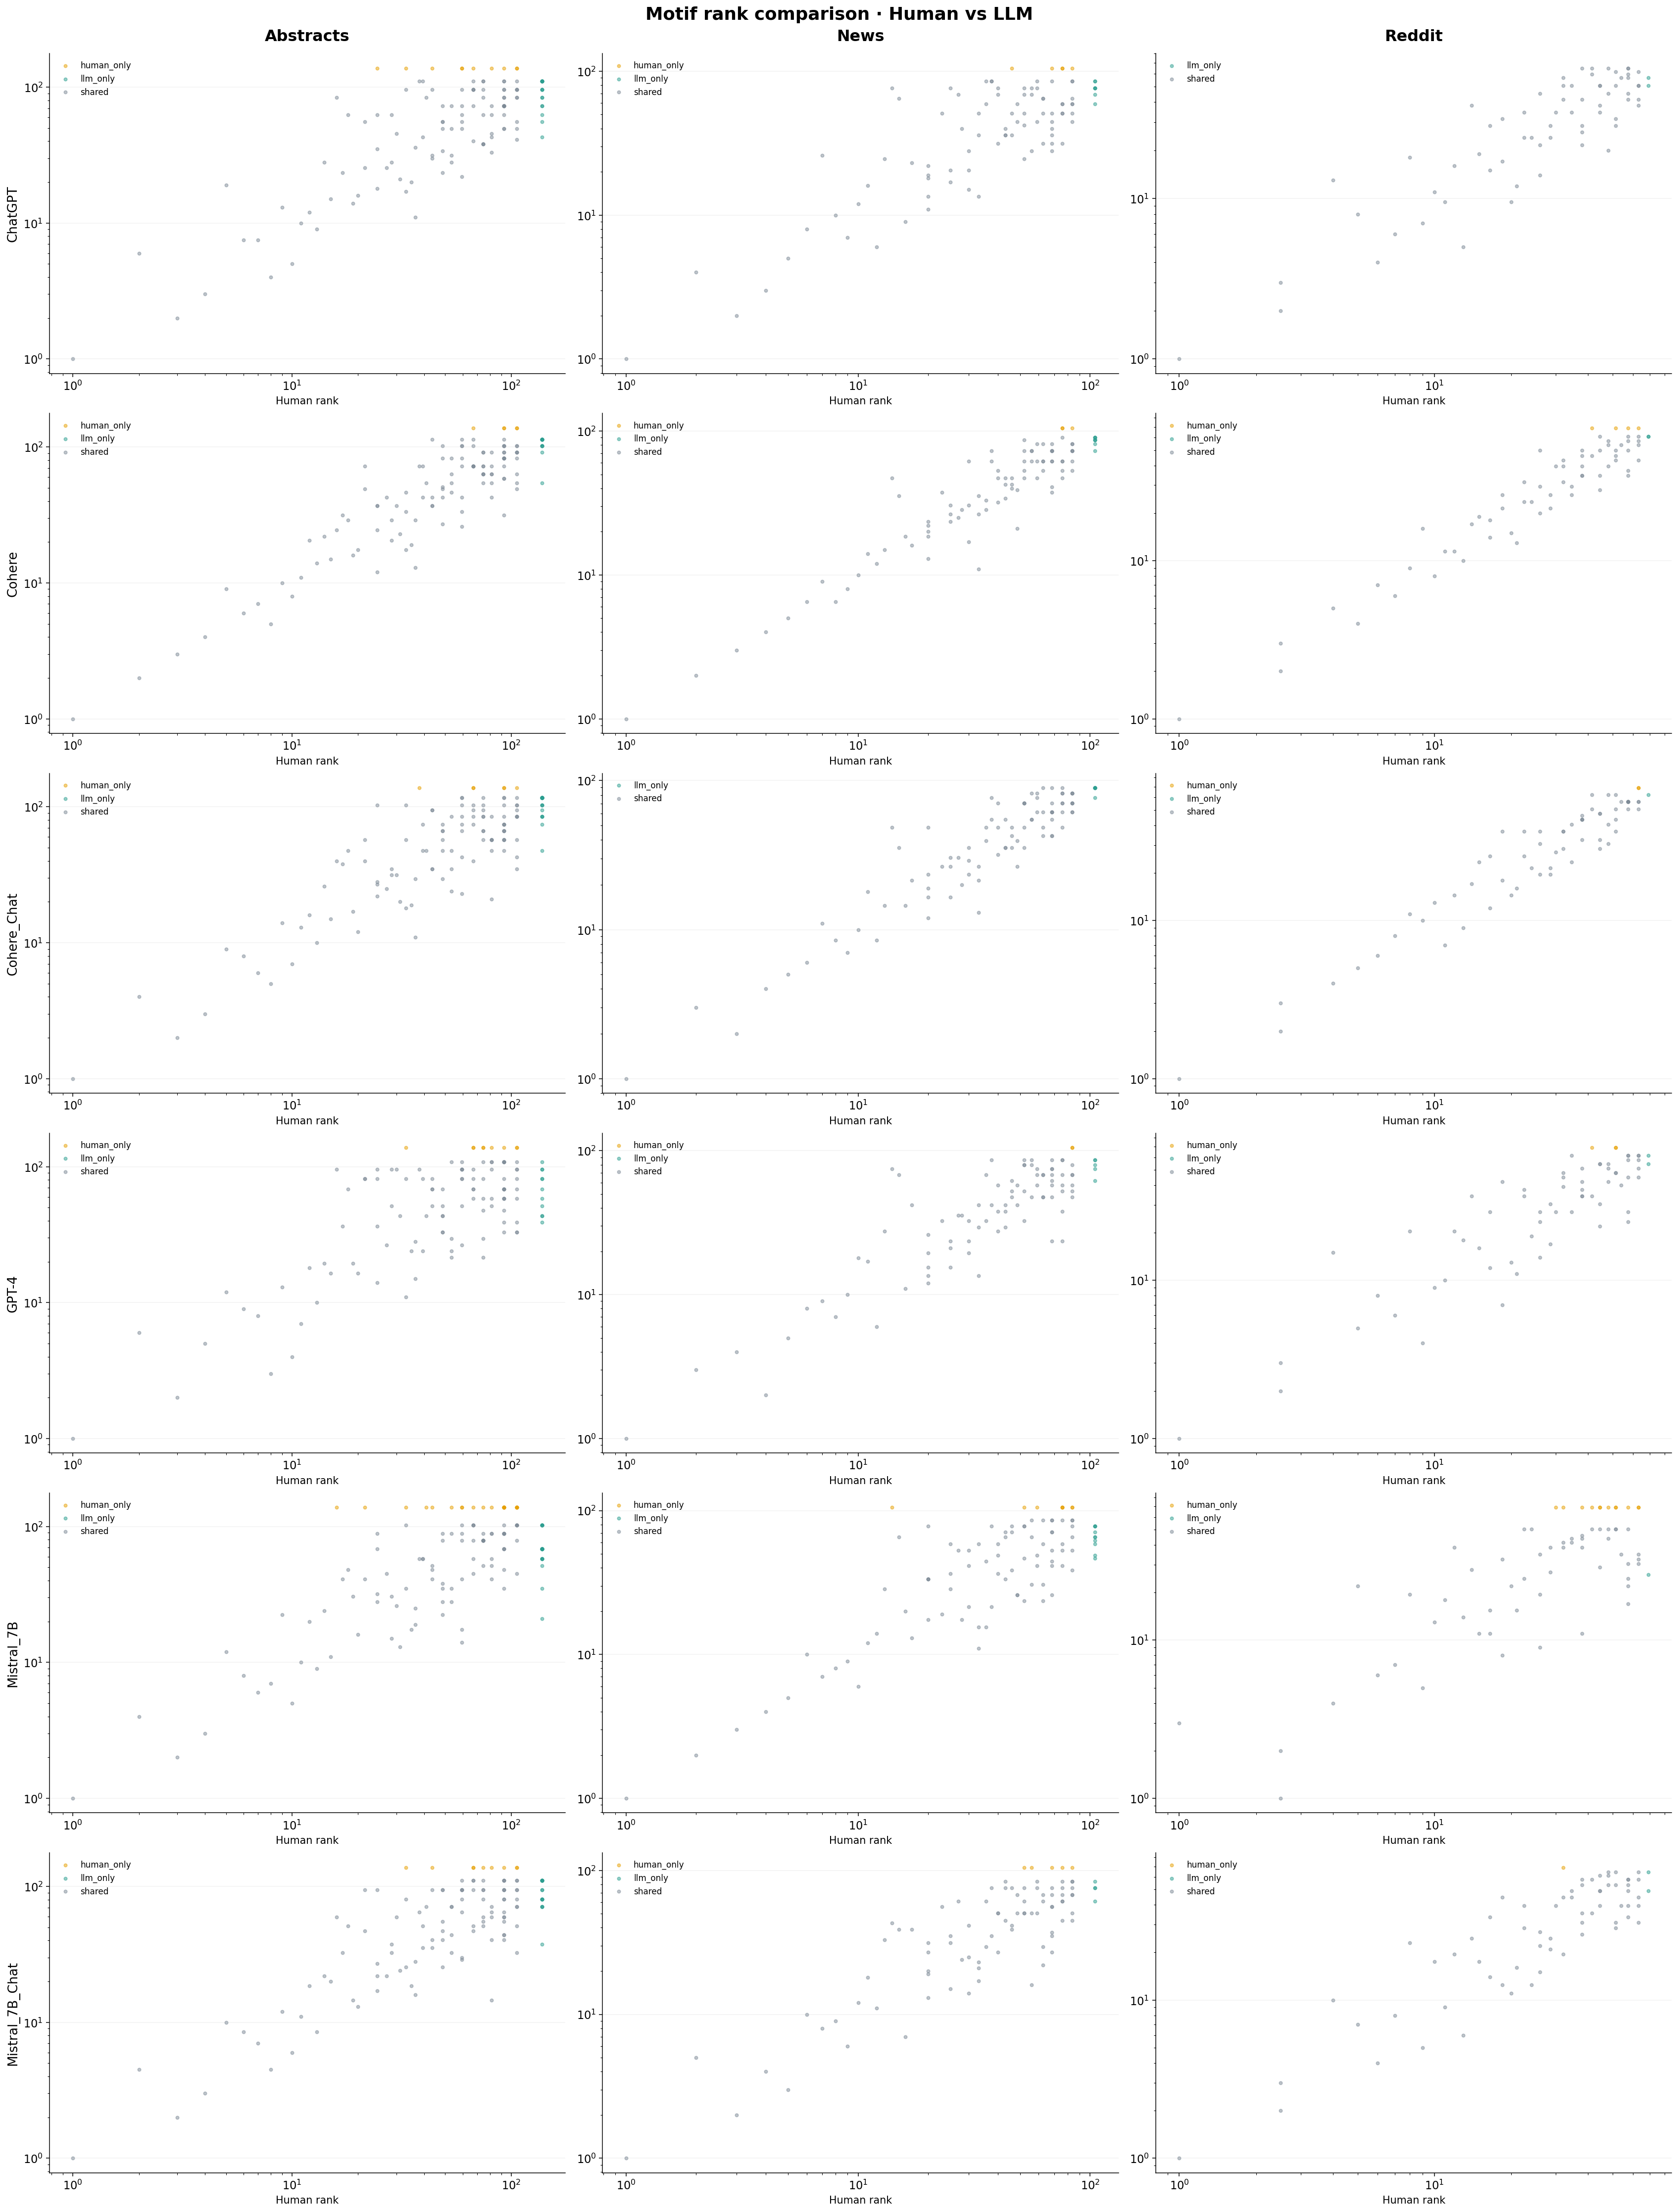

In [65]:
scatter={g:read(g,'divergence','rank_scatter_data') for g in GENRES}
CATEGORY_COLORS={'shared':'#7c8995','human_only':'#e69f00','llm_only':'#2a9d8f',
                 'Human-only':'#e69f00','LLM-only':'#2a9d8f'}
def draw_scatter(ax,g,llm):
    sub=scatter[g].loc[scatter[g].source.eq(llm)]
    for cat,part in sub.groupby('category'):
        ax.scatter(part.plot_human_rank,part.plot_source_rank,
                   s=11,alpha=.48,color=CATEGORY_COLORS.get(cat,'#808080'),
                   label=str(cat),rasterized=True)
    ax.set_xscale('log');ax.set_yscale('log')
    ax.set_xlabel('Human rank')
    ax.legend(fontsize=9,frameon=False,loc='best')
genre_grid([(s,s) for s in LLMS],draw_scatter,
           'rank_scatter_comparison','Motif rank comparison · Human vs LLM',
           row_h=5.5)

In [66]:
def format_js(df, source_col):
    return df.assign(
        js=df.js_divergence_bits.map(lambda x:f'{x:.4f}'),
        ci=df.apply(lambda r:f'[{r.ci_low:.4f}, {r.ci_high:.4f}]',axis=1)
    ).set_index(source_col)[['js','ci']].rename(columns={'js':'JSD (bits)','ci':'95% CI'})

def js_table(kind):
    panels=[]
    for g in GENRES:
        df=read(g,'divergence',kind)
        if kind=='js_human_vs_llm':
            sub=format_js(df,'llm_source')
        else:
            sub=df.copy()
            sub['pair']=sub.apply(lambda r:' vs '.join(sorted([str(r.source_a),str(r.source_b)])),axis=1)
            sub=format_js(sub,'pair')
        sub.columns=pd.MultiIndex.from_product([[g.title()],sub.columns])
        panels.append(sub)
    result=pd.concat(panels,axis=1)
    if kind=='js_human_vs_llm':
        result=result.reindex(LLMS)
        result.index.name='LLM'
    else: result.index.name='LLM pair'
    return result

human_js=js_table('js_human_vs_llm')
display(human_js.style.set_caption('Jensen–Shannon divergence · Human vs LLM')
        .set_table_styles([{'selector':'th','props':[('text-align','center')]}]))
human_js.to_csv(OUT/'js_human_vs_llm_cross_genre.csv')


In [67]:
llm_js=js_table('js_llm_vs_llm')
display(llm_js.style.set_caption('Jensen–Shannon divergence · LLM vs LLM')
        .set_table_styles([{'selector':'th','props':[('text-align','center')]}]))
llm_js.to_csv(OUT/'js_llm_vs_llm_cross_genre.csv')
